Dataset Shape: (1000, 16)

First 5 records:
   Age  Gender  ...   Chest Pain Type  Heart Disease
0   75  Female  ...   Atypical Angina              1
1   48    Male  ...    Typical Angina              0
2   53    Male  ...   Atypical Angina              1
3   69  Female  ...  Non-anginal Pain              0
4   62  Female  ...      Asymptomatic              0

[5 rows x 16 columns]

Processed Data Shape:
(1000, 27)

PCA Transformed Data:
   Principal Component 1  Principal Component 2
0               0.014498               0.006885
1               1.327783              -1.536746
2              -0.344586               2.189857
3              -0.724487               0.102921
4              -2.001347              -0.278023

Explained Variance Ratio:
[0.09800253 0.09356834]

Total Variance Explained:
0.1915708662733832

Percentage of Variance Explained: 19.15708662733832 %


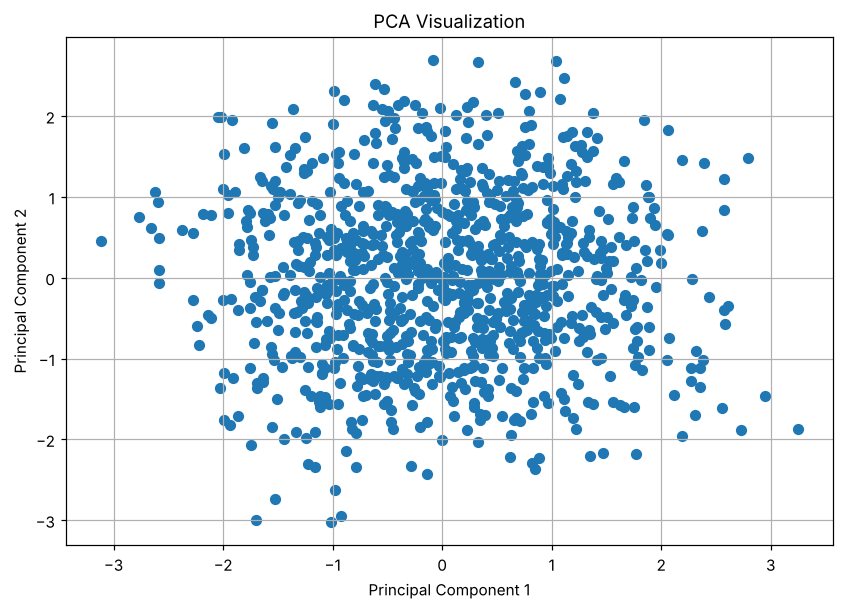

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA

df = pd.read_csv("heart_disease_dataset.csv")

print("Dataset Shape:", df.shape)

print("\nFirst 5 records:")
print(df.head())

X = df.drop("Heart Disease", axis=1)

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

X_processed = preprocessor.fit_transform(X)

# Check whether X_processed is sparse or already a NumPy array
if hasattr(X_processed, "toarray"):
    X_processed = X_processed.toarray()

print("\nProcessed Data Shape:")
print(X_processed.shape)

pca = PCA(
    n_components=2
)

X_pca = pca.fit_transform(X_processed)

pca_df = pd.DataFrame(
    X_pca,
    columns=[
        "Principal Component 1",
        "Principal Component 2"
    ]
)

print("\nPCA Transformed Data:")
print(pca_df.head())

print("\nExplained Variance Ratio:")

print(pca.explained_variance_ratio_)

total_variance = pca.explained_variance_ratio_.sum()

print("\nTotal Variance Explained:")
print(total_variance)

print(
    "\nPercentage of Variance Explained:",
    total_variance * 100,
    "%"
)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    s=40
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA Visualization")

plt.grid(True)

plt.show()
